# Tutorial 8: Object Detection with a Custom Faster R-CNN in PyTorch

## Block 1: Import libraries

In [1]:
import time
import random
import shutil
import zipfile
import xml.etree.ElementTree as ET
from pathlib import Path
import yaml
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torch.nn as nn
import torchvision.transforms.functional as TF
from torchvision.ops import roi_align
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps
from google.colab import files

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
random.seed(42)
torch.manual_seed(42)
print('Device:', device)

Device: cuda


## Block 2: Construct the backbone

In [2]:
def build_backbone(filters=(64, 128, 256, 512)):
    layers = []
    in_channels = 3
    for i, f in enumerate(filters):
        layers += [nn.Conv2d(in_channels, f, 3, padding=1), nn.ReLU()]
        if i < len(filters) - 1:
            layers.append(nn.MaxPool2d(2))
        in_channels = f
    return nn.Sequential(*layers)


backbone = build_backbone()
print(backbone)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (10): ReLU()
)


## Block 3: Construct the Region Proposal Network (RPN)

In [3]:
class RPN(nn.Module):
    def __init__(self, in_channels=512, num_anchors=9):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, 512, 3, padding=1)
        self.cls = nn.Conv2d(512, num_anchors * 2, 1)   # 9 anchors, 2 classes (object / non-object)
        self.bbox = nn.Conv2d(512, num_anchors * 4, 1)  # 9 anchors, 4 bounding box values

    def forward(self, feature_map):
        x = torch.relu(self.conv(feature_map))
        return torch.sigmoid(self.cls(x)), self.bbox(x)

## Block 4: ROI pooling layer

In [4]:
class ROIPoolingLayer(nn.Module):
    def __init__(self, pool_size=(7, 7)):
        super().__init__()
        self.pool_size = pool_size

    def forward(self, feature_map, rois):
        # rois are normalized [ymin, xmin, ymax, xmax], the same format as tf.image.crop_and_resize
        h, w = feature_map.shape[2:]
        ymin, xmin, ymax, xmax = rois.unbind(1)
        boxes = torch.stack([xmin * w, ymin * h, xmax * w, ymax * h], dim=1)
        return roi_align(feature_map, [boxes], output_size=self.pool_size, aligned=True)


roi_pooling_layer = ROIPoolingLayer((7, 7))

## Block 5: Classification and regression heads

In [5]:
class Heads(nn.Module):
    def __init__(self, in_features, num_classes):
        super().__init__()
        self.flatten = nn.Flatten()
        self.dense = nn.Linear(in_features, 1024)
        self.classifier = nn.Linear(1024, num_classes)
        self.bbox_regressor = nn.Linear(1024, num_classes * 4)  # 4 values per bounding box

    def forward(self, pooled_rois):
        x = torch.relu(self.dense(self.flatten(pooled_rois)))
        return torch.softmax(self.classifier(x), dim=1), self.bbox_regressor(x)

## Block 6: Assemble the complete Faster R-CNN model

In [6]:
class FasterRCNN(nn.Module):
    def __init__(self, num_classes, filters=(64, 128, 256, 512)):
        super().__init__()
        self.backbone = build_backbone(filters)
        self.rpn = RPN(filters[-1])
        self.roi_pooling = ROIPoolingLayer((7, 7))
        self.heads = Heads(filters[-1] * 7 * 7, num_classes)

    def forward(self, image, rois):
        feature_map = self.backbone(image)
        rpn_class, rpn_bbox = self.rpn(feature_map)
        pooled_rois = self.roi_pooling(feature_map, rois)
        classifier, bbox_regressor = self.heads(pooled_rois)
        return rpn_class, rpn_bbox, classifier, bbox_regressor

## Block 7: Model summary

In [7]:
def count_params(module):
    return sum(p.numel() for p in module.parameters())


def summary(model, input_size=224, num_rois=5):
    image = torch.zeros(1, 3, input_size, input_size)
    rois = torch.tensor([[0.1, 0.1, 0.5, 0.5]] * num_rois)
    with torch.no_grad():
        feature_map = model.backbone(image)
        rpn_class, rpn_bbox, classifier, bbox_regressor = model(image, rois)

    print(f"{'Part':14} {'Parameters':>12}")
    for name, part in [('Backbone', model.backbone), ('RPN', model.rpn), ('Heads', model.heads)]:
        print(f"{name:14} {count_params(part):12,}")
    print(f"{'Total':14} {count_params(model):12,}\n")

    print('Input image:   ', tuple(image.shape))
    print('Feature map:   ', tuple(feature_map.shape))
    print('RPN class:     ', tuple(rpn_class.shape))
    print('RPN bbox:      ', tuple(rpn_bbox.shape))
    print('Classifier:    ', tuple(classifier.shape))
    print('BBox regressor:', tuple(bbox_regressor.shape))


num_classes = 80  # COCO dataset
faster_rcnn = FasterRCNN(num_classes)
print(faster_rcnn)
summary(faster_rcnn)

FasterRCNN(
  (backbone): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
  )
  (rpn): RPN(
    (conv): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (cls): Conv2d(512, 18, kernel_size=(1, 1), stride=(1, 1))
    (bbox): Conv2d(512, 36, kernel_size=(1, 1), stride=(1, 1))
  )
  (roi_pooling): ROIPoolingLayer()
  (heads): Heads(
    (flatten): Flatten(start_dim=1, end_dim=-1)
    (dense): 

## Block 8: Calculate IoU

In [8]:
def calculate_iou(box1, box2):
    ymin1, xmin1, ymax1, xmax1 = box1
    ymin2, xmin2, ymax2, xmax2 = box2
    inter_xmin = max(xmin1, xmin2)
    inter_ymin = max(ymin1, ymin2)
    inter_xmax = min(xmax1, xmax2)
    inter_ymax = min(ymax1, ymax2)
    inter_area = max(0, inter_xmax - inter_xmin) * max(0, inter_ymax - inter_ymin)
    area1 = (xmax1 - xmin1) * (ymax1 - ymin1)
    area2 = (xmax2 - xmin2) * (ymax2 - ymin2)
    union_area = area1 + area2 - inter_area
    iou = inter_area / union_area if union_area != 0 else 0
    return iou

## Block 9: Calculate precision and recall

In [9]:
def calculate_precision_recall(pred_boxes, pred_scores, pred_labels, gt_boxes, gt_labels, iou_threshold=0.5):
    tp, fp = 0, 0
    matched_gt = set()
    for i, pred_box in enumerate(pred_boxes):
        if pred_scores[i] < iou_threshold:
            continue
        best_iou = 0
        best_gt_index = -1
        for j, gt_box in enumerate(gt_boxes):
            if pred_labels[i] == gt_labels[j] and j not in matched_gt:
                iou = calculate_iou(pred_box, gt_box)
                if iou > best_iou:
                    best_iou = iou
                    best_gt_index = j
        if best_iou >= iou_threshold:
            tp += 1
            matched_gt.add(best_gt_index)
        else:
            fp += 1
    fn = len(gt_boxes) - len(matched_gt)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    return precision, recall

## Block 10: Calculate average precision and mAP

In [10]:
def calculate_ap(precisions, recalls):
    precisions = [0.0] + precisions + [0.0]
    recalls = [0.0] + recalls + [1.0]
    for i in range(len(precisions) - 1, 0, -1):
        precisions[i - 1] = max(precisions[i - 1], precisions[i])
    indices = [i for i in range(1, len(recalls)) if recalls[i] != recalls[i - 1]]
    ap = sum((recalls[i] - recalls[i - 1]) * precisions[i] for i in indices)
    return ap


def calculate_map(predictions, ground_truths, num_classes, iou_threshold=0.5):
    average_precisions = []
    for class_id in range(1, num_classes):  # class 0 is background
        all_precisions = []
        all_recalls = []
        for pred, gt in zip(predictions, ground_truths):
            pred_boxes = [box for i, box in enumerate(pred['boxes']) if pred['labels'][i] == class_id]
            pred_scores = [score for i, score in enumerate(pred['scores']) if pred['labels'][i] == class_id]
            gt_boxes = [box for i, box in enumerate(gt['boxes']) if gt['labels'][i] == class_id]
            precision, recall = calculate_precision_recall(
                pred_boxes, pred_scores, [class_id] * len(pred_boxes),
                gt_boxes, [class_id] * len(gt_boxes), iou_threshold
            )
            all_precisions.append(precision)
            all_recalls.append(recall)
        ap = calculate_ap(all_precisions, all_recalls)
        average_precisions.append(ap)
    mAP = np.mean(average_precisions)
    return mAP

## Block 11: Sample values for obtaining mAP

In [11]:
predictions = [
    {'boxes': [[0.1, 0.1, 0.4, 0.4], [0.5, 0.5, 0.8, 0.8]], 'scores': [0.9, 0.7], 'labels': [1, 2]}
]
ground_truths = [
    {'boxes': [[0.12, 0.12, 0.42, 0.42], [0.5, 0.5, 0.8, 0.8]], 'labels': [1, 2]}
]

num_classes = 80  # COCO dataset
mean_ap = calculate_map(predictions, ground_truths, num_classes)
print(f"Mean Average Precision (mAP): {mean_ap:.2f}")

print("IoU of the two class 1 boxes:", round(calculate_iou(predictions[0]['boxes'][0], ground_truths[0]['boxes'][0]), 3))

# Only classes 1 and 2 appear here, so with 80 classes the other 77 classes
# have AP = 0 and pull the average down. Counting only the classes that appear:
print(f"Mean Average Precision (mAP), num_classes=3: {calculate_map(predictions, ground_truths, 3):.2f}")

Mean Average Precision (mAP): 0.03
IoU of the two class 1 boxes: 0.772
Mean Average Precision (mAP), num_classes=3: 1.00


## Block 12: Task 1 - Change the number of layers

In [12]:
configs = {
    'Shallower (3 conv layers)': (64, 128, 512),
    'Original (4 conv layers)': (64, 128, 256, 512),
    'Deeper (5 conv layers)': (64, 128, 256, 512, 512),
    'Deeper (6 conv layers)': (64, 128, 256, 512, 512, 512),
}

image = torch.zeros(1, 3, 224, 224).to(device)
rois = torch.tensor([[0.1, 0.1, 0.5, 0.5]] * 5).to(device)

print(f"{'Model':28} {'Backbone params':>16} {'Total params':>13} {'Feature map':>12} {'Anchors':>8} {'Time (ms)':>10}")
for name, filters in configs.items():
    model = FasterRCNN(80, filters).to(device).eval()
    with torch.no_grad():
        feature_map = model.backbone(image)
        model(image, rois)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = time.time()
        for _ in range(10):
            model(image, rois)
        if device.type == 'cuda':
            torch.cuda.synchronize()
    t = (time.time() - start) / 10 * 1000
    h, w = feature_map.shape[2:]
    print(f"{name:28} {count_params(model.backbone):16,} {count_params(model):13,} "
          f"{f'{h}x{w}':>12} {h * w * 9:8,} {t:10.2f}")

Model                         Backbone params  Total params  Feature map  Anchors  Time (ms)
Shallower (3 conv layers)             665,984    29,154,630        56x56   28,224       7.95
Original (4 conv layers)            1,550,976    30,039,622        28x28    7,056       5.46
Deeper (5 conv layers)              3,910,784    32,399,430        14x14    1,764       4.91
Deeper (6 conv layers)              6,270,592    34,759,238          7x7      441       5.32


## Block 13: Task 2 - Test on an image

Saving test image.jpg to test image.jpg
Custom model (untrained):
Average objectness score: 0.497
ROI 1: class 8 with probability 0.0129
ROI 2: class 34 with probability 0.0128
ROI 3: class 8 with probability 0.0129
ROI 4: class 8 with probability 0.0129
ROI 5: class 8 with probability 0.0129
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 197MB/s]



Pretrained Faster R-CNN detections (score > 0.5):
  traffic light 1.00
  car 0.99
  traffic light 0.99
  traffic light 0.99
  car 0.99
  car 0.99
  car 0.98
  car 0.98
  car 0.97
  traffic light 0.94
  car 0.92
  car 0.90
  car 0.78
  car 0.69


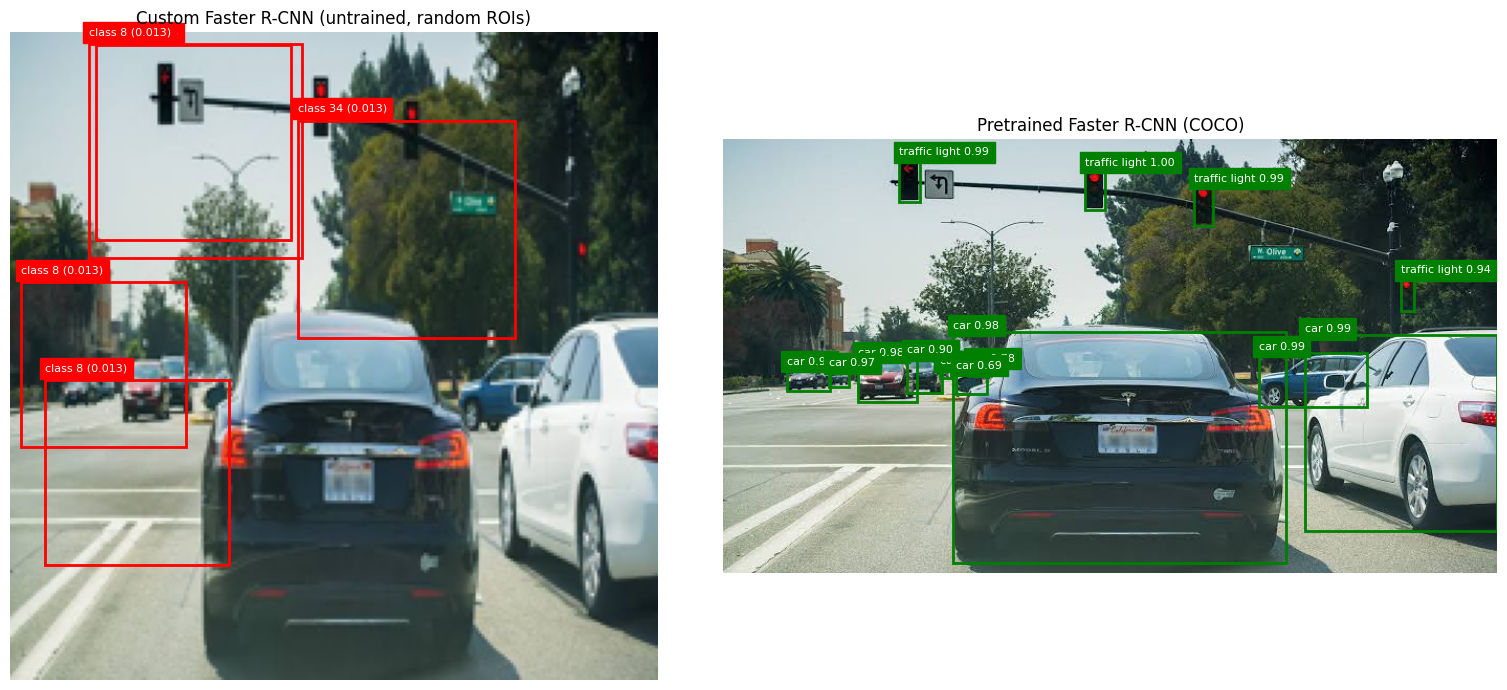

In [13]:
def draw_boxes(ax, boxes, texts, color):
    for box, text in zip(boxes, texts):
        x1, y1, x2, y2 = box
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2))
        ax.text(x1, y1 - 3, text, color='white', fontsize=8, backgroundcolor=color)


uploaded = files.upload()
img_path = list(uploaded.keys())[0]
img = Image.open(img_path).convert('RGB')

# a) Our custom Faster R-CNN (untrained) with 5 random ROIs
img_224 = img.resize((224, 224))
image = TF.to_tensor(img_224).unsqueeze(0).to(device)
rois = []
for _ in range(5):
    y, x = random.uniform(0, 0.6), random.uniform(0, 0.6)
    size = random.uniform(0.2, 0.4)
    rois.append([y, x, y + size, x + size])
rois = torch.tensor(rois).to(device)

faster_rcnn = FasterRCNN(80).to(device).eval()
with torch.no_grad():
    rpn_class, rpn_bbox, classifier, bbox_regressor = faster_rcnn(image, rois)

probs, classes = classifier.max(dim=1)
print('Custom model (untrained):')
print('Average objectness score:', round(rpn_class.mean().item(), 3))
for i in range(len(rois)):
    print(f"ROI {i + 1}: class {classes[i].item()} with probability {probs[i].item():.4f}")

# b) Pretrained Faster R-CNN (ResNet50 + FPN, trained on COCO)
weights = FasterRCNN_ResNet50_FPN_Weights.COCO_V1
coco_names = weights.meta['categories']
detector = fasterrcnn_resnet50_fpn(weights=weights).to(device).eval()
with torch.no_grad():
    output = detector([TF.to_tensor(img).to(device)])[0]

keep = output['scores'] > 0.5
det_boxes = output['boxes'][keep].cpu().tolist()
det_texts = [f"{coco_names[l]} {s:.2f}" for l, s in zip(output['labels'][keep].tolist(), output['scores'][keep].tolist())]
print('\nPretrained Faster R-CNN detections (score > 0.5):')
for text in det_texts:
    print(' ', text)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].imshow(img_224)
roi_pixels = (rois[:, [1, 0, 3, 2]] * 224).cpu().tolist()
draw_boxes(axes[0], roi_pixels, [f"class {c} ({p:.3f})" for c, p in zip(classes.tolist(), probs.tolist())], 'red')
axes[0].set_title('Custom Faster R-CNN (untrained, random ROIs)')
axes[0].axis('off')
axes[1].imshow(img)
draw_boxes(axes[1], det_boxes, det_texts, 'green')
axes[1].set_title('Pretrained Faster R-CNN (COCO)')
axes[1].axis('off')
plt.tight_layout()
plt.show()

## Block 14: Task 3 - Read the boxes drawn on the images

In [14]:
# Reads the boxes back from images that have labelled boxes drawn on them
# (e.g. Annotated_Images.zip): every class was drawn in its own exact colour with a name tag,
# so each tag is found by exact template matching and its rectangle is traced from the line pixels.
# The drawings are then painted out (inpainting) so the detectors are tested on clean pictures.
# Colours used when the boxes were drawn (RGB), one per class
CLASS_COLORS = {
    'trafficlight': (255, 193, 7),
    'stop': (220, 53, 69),
    'speedlimit': (0, 123, 255),
    'crosswalk': (40, 167, 69),
}


def draw_style(shape):
    h, w = shape[:2]
    return max(2, round(min(h, w) / 150)), max(0.4, min(h, w) / 600)


def tag_size(name, shape):
    _, fs = draw_style(shape)
    (tw, th), base = cv2.getTextSize(name, cv2.FONT_HERSHEY_SIMPLEX, fs, 1)
    return tw, th, base


def draw_box(canvas, name, x1, y1, x2, y2, color, outline=True, tag=True):
    # Same drawing routine that produced the annotated images
    t, fs = draw_style(canvas.shape)
    tw, th, base = tag_size(name, canvas.shape)
    if outline:
        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, t)
    if tag:
        ty = max(y1, th + base + 4)
        cv2.rectangle(canvas, (x1, ty - th - base - 4), (x1 + tw + 6, ty), color, -1)
        cv2.putText(canvas, name, (x1 + 3, ty - base - 2), cv2.FONT_HERSHEY_SIMPLEX,
                    fs, (255, 255, 255), 1, cv2.LINE_AA)


def tag_template(name, color, shape):
    tw, th, base = tag_size(name, shape)
    th_tag = th + base + 4
    tmpl = np.zeros(shape, np.uint8)
    draw_box(tmpl, name, 0, th_tag, 1, th_tag + 1, color, outline=False)
    return (tmpl[:th_tag + 1, :tw + 7] == np.array(color, np.uint8)).all(-1).astype(np.float32), th_tag


def find_all_tags(img):
    # Locate every label tag by matching the exact rendered tag. Tags already found (and other
    # classes' drawings) are treated as wildcards, so a tag partly hidden under another is still found.
    h, w = img.shape[:2]
    masks = {n: (img == np.array(c, np.uint8)).all(-1) for n, c in CLASS_COLORS.items()}
    any_col = np.zeros((h, w), bool)
    for m in masks.values():
        any_col |= m
    found = []
    W = np.zeros((h, w), np.float32)  # wildcard pixels: covered by a tag found earlier
    while True:
        best = None
        for name, color in CLASS_COLORS.items():
            if not masks[name].any():
                continue
            F, th_tag = tag_template(name, color, img.shape)
            th_, tw_ = F.shape
            E = masks[name].astype(np.float32)
            wild = np.maximum(W, (any_col & ~masks[name]).astype(np.float32))
            P = lambda a: cv2.copyMakeBorder(a, 0, th_, 0, tw_, cv2.BORDER_CONSTANT, value=0)
            K = P((1 - wild))            # pixels inside the image that are not wildcards
            Ek = P(E * (1 - wild))
            agree = cv2.matchTemplate(Ek, F, cv2.TM_CCORR) + cv2.matchTemplate(K - Ek, 1 - F, cv2.TM_CCORR)
            known = cv2.matchTemplate(K, np.ones_like(F), cv2.TM_CCORR)
            ratio = np.where(known >= 0.25 * F.size, agree / np.maximum(known, 1), 0)
            y, x = np.unravel_index(np.argmax(ratio), ratio.shape)
            if ratio[y, x] >= 0.92 and (best is None or known[y, x] > best[0]):
                best = (known[y, x], name, int(x), int(y), th_tag, tw_, th_)
        if best is None:
            break
        _, name, x, y, th_tag, tw_, th_ = best
        found.append((name, x, y + th_tag))  # (class, x1, bottom row of the tag)
        W[y:y + th_, x:x + tw_] = 1
    return found


def run_end(line, start):
    # last index of the run of True values that begins at `start`
    i = start
    while i + 1 < len(line) and line[i + 1]:
        i += 1
    return i if line[start] else None


def best_box(mask, covered, free, name, color, shape, x1, y1_options, x2s, y2s, min_y2):
    # Smallest rectangle whose drawn outline is fully supported by the image
    h, w = shape[:2]
    best = None
    for y1 in y1_options:
        cands = sorted(((x2, y2) for x2 in set(x2s) for y2 in set(y2s)
                        if x2 > x1 + 2 and y2 > max(y1 + 2, min_y2)),
                       key=lambda b: (b[0] - x1) * (b[1] - y1))
        for x2, y2 in cands:
            if best is not None and (x2 - x1) * (y2 - y1) >= best[0]:
                break
            canvas = np.zeros(shape, np.uint8)
            draw_box(canvas, name, x1, y1, x2, y2, color, tag=False)
            out = (canvas == np.array(color, np.uint8)).all(-1)
            n = np.count_nonzero(out)
            if n == 0:
                continue
            if np.count_nonzero(out & mask & free) < 0.3 * n:   # a good part must be visibly drawn in this colour
                continue
            if np.count_nonzero(out & covered) >= 0.95 * n:
                best = ((x2 - x1) * (y2 - y1), (x1, y1, min(x2, w - 1), min(y2, h - 1)))
                break
    return best[1] if best else None


def edge_candidates(covered, mask, other_tags, x1, y1, t, shape):
    h, w = shape[:2]
    k = max(4, 2 * t)
    r0, r1 = min(h - 1, y1 + t + 1), min(h, y1 + t + 1 + k)
    c0, c1 = min(w - 1, x1 + t + 1), min(w, x1 + t + 1 + k)
    vert = [covered[r0:r1, c].all() for c in range(w)]
    horz = [covered[r, c0:c1].all() for r in range(h)]
    x2s = [c for c in range(x1 + 3, w) if vert[c] and (c + 1 >= w or not vert[c + 1])]
    y2s = [r for r in range(y1 + 3, h) if horz[r] and (r + 1 >= h or not horz[r + 1])]
    x2s = [c - d for c in x2s for d in range(t + 1)] + [w + 50]
    y2s = [r - d for r in y2s for d in range(t + 1)] + [h + 50]
    for m in (mask, covered):  # where the top edge and the left edge stop
        e = run_end(m[min(h - 1, y1), :], x1) if 0 <= y1 < h else None
        if e is not None:
            x2s += [e - d for d in range(t + 1)]
        e = run_end(m[:, x1], max(0, y1))
        if e is not None:
            y2s += [e - d for d in range(t + 1)]
    # edges hidden under other tags
    ys, xs = np.nonzero(other_tags[:, x1:x1 + 1])
    y2s += [int(y) for y in ys if y > y1 + 2]
    if 0 <= y1 < h:
        xs = np.nonzero(other_tags[y1])[0]
        x2s += [int(x) for x in xs if x > x1 + 2]
    return x2s, y2s


def fit_from_tag(img, mask, covered, free, other_tags, name, color, x1, ty, own_tag):
    t, _ = draw_style(img.shape)
    tw, th, base = tag_size(name, img.shape)
    th_tag = th + base + 4
    y1_options = [ty] if ty > th_tag else list(range(0, th_tag + 1))
    best = None
    for y1 in y1_options:
        x2s, y2s = edge_candidates(covered | own_tag, mask, other_tags, x1, y1, t, img.shape)
        box = best_box(mask, covered | own_tag, free, name, color, img.shape,
                       x1, [y1], x2s, y2s, ty + t)
        if box and (best is None or (box[2] - box[0]) * (box[3] - box[1]) < best[0]):
            best = ((box[2] - box[0]) * (box[3] - box[1]), box)
    return best[1] if best else None


def fit_untagged(img, comp, covered, free, other_tags, name, color):
    # Box whose tag is hidden under another tag: start from the lowest visible edge
    h, w = img.shape[:2]
    t, _ = draw_style(img.shape)
    ys, xs = np.nonzero(comp)
    y_bot = ys.max()
    row = xs[ys == y_bot]
    x1, x2 = int(row.min()), int(row.max())
    y2 = int(min(y_bot, h - 1) - t // 2) if y_bot < h - 1 else h + 50
    return best_box(comp, covered, free, name, color, img.shape, x1,
                    range(max(0, int(ys.min()) - 2 * t), y2 - 2), [x2, x2 + 1, x2 - 1], [y2], 0)


def refine(box, mask, covered, tags_area, name, color, shape, move_x1=False, move_y1=False):
    # Nudge the box edges by a pixel or two to best match the drawn line pixels
    h, w = shape[:2]
    t, _ = draw_style(shape)
    x1, y1, x2, y2 = box
    r0, r1 = max(0, y1 - 3 * t), min(h, y2 + 3 * t + 1)
    c0, c1 = max(0, x1 - 3 * t), min(w, x2 + 3 * t + 1)
    target = mask[r0:r1, c0:c1] & ~tags_area[r0:r1, c0:c1]
    cov = covered[r0:r1, c0:c1]
    R = range(-t, t + 1)
    best = None
    for a in (R if move_x1 else [0]):
        for b in (R if move_y1 else [0]):
            for c in R:
                for d in R:
                    bx = (x1 + a, y1 + b, x2 + c, y2 + d)
                    if bx[2] <= bx[0] + 2 or bx[3] <= bx[1] + 2:
                        continue
                    canvas = np.zeros(shape, np.uint8)
                    draw_box(canvas, name, *bx, color, tag=False)
                    out = (canvas == np.array(color, np.uint8)).all(-1)[r0:r1, c0:c1]
                    score = (np.count_nonzero(out & target) - 3 * np.count_nonzero(out & ~cov)
                             - np.count_nonzero(target & ~out))
                    if best is None or score > best[0]:
                        best = (score, bx)
    x1, y1, x2, y2 = best[1]
    return (max(0, x1), max(0, y1), min(w - 1, x2), min(h - 1, y2))


def recover_boxes(img):
    # img: RGB image with boxes drawn on it -> list of (class name, (xmin, ymin, xmax, ymax))
    h, w = img.shape[:2]
    masks = {n: (img == np.array(c, np.uint8)).all(-1) for n, c in CLASS_COLORS.items()}
    tags = find_all_tags(img)
    all_tags = np.zeros((h, w), bool)
    regions = []
    for name, x1, ty in tags:
        tw, th, base = tag_size(name, img.shape)
        r = np.zeros((h, w), bool)
        r[max(0, ty - th - base - 4):ty + 1, x1:x1 + tw + 7] = True
        regions.append(r)
        all_tags |= r
    objects = []
    explained = all_tags.copy()
    for (name, x1, ty), own in zip(tags, regions):
        color = CLASS_COLORS[name]
        other = all_tags & ~own
        for n2, m2 in masks.items():
            if n2 != name:
                other |= m2
        box = fit_from_tag(img, masks[name], masks[name] | other, ~other, all_tags & ~own,
                           name, color, x1, ty, own)
        if box:
            tw, th, base = tag_size(name, img.shape)
            box = refine(box, masks[name], masks[name] | other | own, all_tags, name, color, img.shape,
                         move_y1=ty <= th + base + 4)
            objects.append((name, box))
            canvas = np.zeros(img.shape, np.uint8)
            draw_box(canvas, name, *box, color, tag=False)
            explained |= (canvas == np.array(color, np.uint8)).all(-1)
    # boxes whose tag was hidden: colour pixels that no box explains yet
    explained = cv2.dilate(explained.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)
    for name, color in CLASS_COLORS.items():
        left = masks[name] & ~explained
        n, labels, stats, _ = cv2.connectedComponentsWithStats(left.astype(np.uint8), connectivity=8)
        for i in range(1, n):
            if stats[i, cv2.CC_STAT_AREA] < 40:
                continue
            other = all_tags.copy()
            for n2, m2 in masks.items():
                if n2 != name:
                    other |= m2
            box = fit_untagged(img, labels == i, masks[name] | other | explained, ~other, all_tags, name, color)
            if box:
                box = refine(box, masks[name], masks[name] | other | explained, all_tags, name, color,
                             img.shape, move_x1=True, move_y1=True)
                objects.append((name, box))
    return objects


def clean_image(img, objects):
    # Paint over the drawn boxes and tags so the detectors see the original picture
    h, w = img.shape[:2]
    any_col = np.zeros((h, w), bool)
    for c in CLASS_COLORS.values():
        any_col |= (img == np.array(c, np.uint8)).all(-1)
    footprint = np.zeros((h, w), np.uint8)
    for name, box in objects:
        canvas = np.zeros(img.shape, np.uint8)
        draw_box(canvas, name, *box, CLASS_COLORS[name])
        footprint |= canvas.any(-1).astype(np.uint8)
    footprint = cv2.dilate(footprint | any_col.astype(np.uint8), np.ones((3, 3), np.uint8))
    return cv2.inpaint(img, footprint, 3, cv2.INPAINT_TELEA)

## Block 15: Task 3 - Upload and read the labelled dataset

In [15]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
MAX_IMAGES = 150   # how many labelled images to use (None = all)
SEED = 42          # same seed = same images every run


def open_image(path):
    # exif_transpose rotates phone photos the same way labelling tools display them
    return ImageOps.exif_transpose(Image.open(path)).convert('RGB')


def read_yolo_names(root):
    # Class names from classes.txt / obj.names / data.yaml (Roboflow, LabelImg, makesense)
    for txt in list(root.rglob('classes.txt')) + list(root.rglob('*.names')):
        names = [line.strip() for line in open(txt) if line.strip()]
        if names:
            return names
    for yml in list(root.rglob('data.yaml')) + list(root.rglob('*.yaml')):
        try:
            names = yaml.safe_load(open(yml)).get('names')
        except Exception:
            continue
        if isinstance(names, dict):
            names = [names[k] for k in sorted(names)]
        if names:
            return [str(n) for n in names]
    return []


def pick(paths):
    # random but repeatable subset
    paths = sorted(paths)
    random.Random(SEED).shuffle(paths)
    return paths


def load_labelled_zip(zip_path, extract_dir):
    shutil.rmtree(extract_dir, ignore_errors=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(extract_dir)
    root = Path(extract_dir)

    def usable(p):
        return '__MACOSX' not in p.parts and not p.name.startswith('.')

    images = {p.stem: p for p in root.rglob('*') if p.suffix.lower() in IMAGE_EXTS and usable(p)}
    xml_files = [p for p in root.rglob('*.xml') if usable(p)]
    txt_files = [p for p in root.rglob('*.txt') if usable(p) and p.name not in ('classes.txt', 'README.txt')]
    samples, skipped = [], 0
    enough = lambda: MAX_IMAGES is not None and len(samples) >= MAX_IMAGES

    if xml_files:
        label_format = 'Pascal VOC (.xml)'
        for xml_path in pick(xml_files):
            if enough():
                break
            ann = ET.parse(xml_path).getroot()
            img_path = images.get(xml_path.stem) or images.get(Path(ann.findtext('filename', '')).stem)
            if img_path is None:
                skipped += 1
                continue
            width, height = open_image(img_path).size
            xml_w = float(ann.findtext('size/width') or 0) or width
            xml_h = float(ann.findtext('size/height') or 0) or height
            sx, sy = width / xml_w, height / xml_h  # in case the image was resized after labelling
            objects = []
            for obj in ann.iter('object'):
                bb = obj.find('bndbox')
                x1, y1, x2, y2 = (float(bb.findtext(k)) for k in ('xmin', 'ymin', 'xmax', 'ymax'))
                box = [max(0, x1 * sx), max(0, y1 * sy), min(width, x2 * sx), min(height, y2 * sy)]
                if box[2] - box[0] > 1 and box[3] - box[1] > 1:
                    objects.append((obj.findtext('name').strip(), box))
            samples.append((img_path, objects))
    elif txt_files:
        label_format = 'YOLO (.txt)'
        names = read_yolo_names(root)
        for txt_path in pick(txt_files):
            if enough():
                break
            img_path = images.get(txt_path.stem)
            if img_path is None:
                skipped += 1
                continue
            width, height = open_image(img_path).size
            objects = []
            for line in open(txt_path):
                values = line.split()
                if len(values) < 5:
                    continue
                cls = int(float(values[0]))
                xc, yc, bw, bh = (float(v) for v in values[1:5])
                box = [max(0, (xc - bw / 2) * width), max(0, (yc - bh / 2) * height),
                       min(width, (xc + bw / 2) * width), min(height, (yc + bh / 2) * height)]
                if box[2] - box[0] > 1 and box[3] - box[1] > 1:
                    name = names[cls] if cls < len(names) else f'class_{cls}'
                    objects.append((name.strip(), box))
            samples.append((img_path, objects))
    elif images:
        # No label files: read the boxes from the colours drawn on the images
        label_format = 'boxes drawn on the images (read from their colours)'
        clean_dir = root / '_clean'
        clean_dir.mkdir(exist_ok=True)
        todo = pick(list(images.values()))
        print(f'Reading the drawn boxes from {len(todo)} images...')
        for k, img_path in enumerate(todo):
            if enough():
                break
            img = np.array(open_image(img_path))
            objects = recover_boxes(img)
            if not objects:
                skipped += 1
                continue
            clean_path = clean_dir / (img_path.stem + '.png')
            Image.fromarray(clean_image(img, objects)).save(clean_path)
            samples.append((clean_path, [(name, [float(v) for v in box]) for name, box in objects]))
            if (k + 1) % 25 == 0:
                print(f'  {k + 1} images done')
    else:
        raise ValueError('No images or label files found in the zip.')

    if not samples:
        raise ValueError('No labelled images found. Use a zip with images + .xml/.txt label files, or '
                         'images with the boxes drawn on them.')

    print('Label format:', label_format)
    print('Labelled images used:', len(samples))
    if skipped:
        print('Images skipped (no labels found):', skipped)
    counts = {}
    for _, objects in samples:
        for name, _ in objects:
            counts[name] = counts.get(name, 0) + 1
    for name, n in sorted(counts.items()):
        print(f'  {name}: {n} objects')
    return samples


# Upload the same zip as Tutorial 8 (images with the boxes drawn on them, or images + .xml/.txt labels)
uploaded = files.upload()
zip_name = next(name for name in uploaded if name.lower().endswith('.zip'))
samples = load_labelled_zip(zip_name, '/content/dataset')

class_names = sorted({name for _, objects in samples for name, _ in objects})
class_to_id = {name: i + 1 for i, name in enumerate(class_names)}  # 0 is background
print('Classes:', class_names)

random.Random(42).shuffle(samples)
split = int(0.8 * len(samples))
train_samples, test_samples = samples[:split], samples[split:]
print('Training images:', len(train_samples))
print('Test images:', len(test_samples))
for name in class_names:
    n_train = sum(1 for _, objs in train_samples for n, _ in objs if n == name)
    n_test = sum(1 for _, objs in test_samples for n, _ in objs if n == name)
    print(f"  {name:14} train: {n_train:4}   test: {n_test:4}")

Saving Annotated Images.zip to Annotated Images.zip
Reading the drawn boxes from 150 images...
  25 images done
  50 images done
  75 images done
  100 images done
  125 images done
  150 images done
Label format: boxes drawn on the images (read from their colours)
Labelled images used: 149
Images skipped (no labels found): 1
  crosswalk: 34 objects
  speedlimit: 123 objects
  stop: 17 objects
  trafficlight: 19 objects
Classes: ['crosswalk', 'speedlimit', 'stop', 'trafficlight']
Training images: 119
Test images: 30
  crosswalk      train:   26   test:    8
  speedlimit     train:  101   test:   22
  stop           train:   13   test:    4
  trafficlight   train:   16   test:    3


## Block 16: Dataset and data loaders

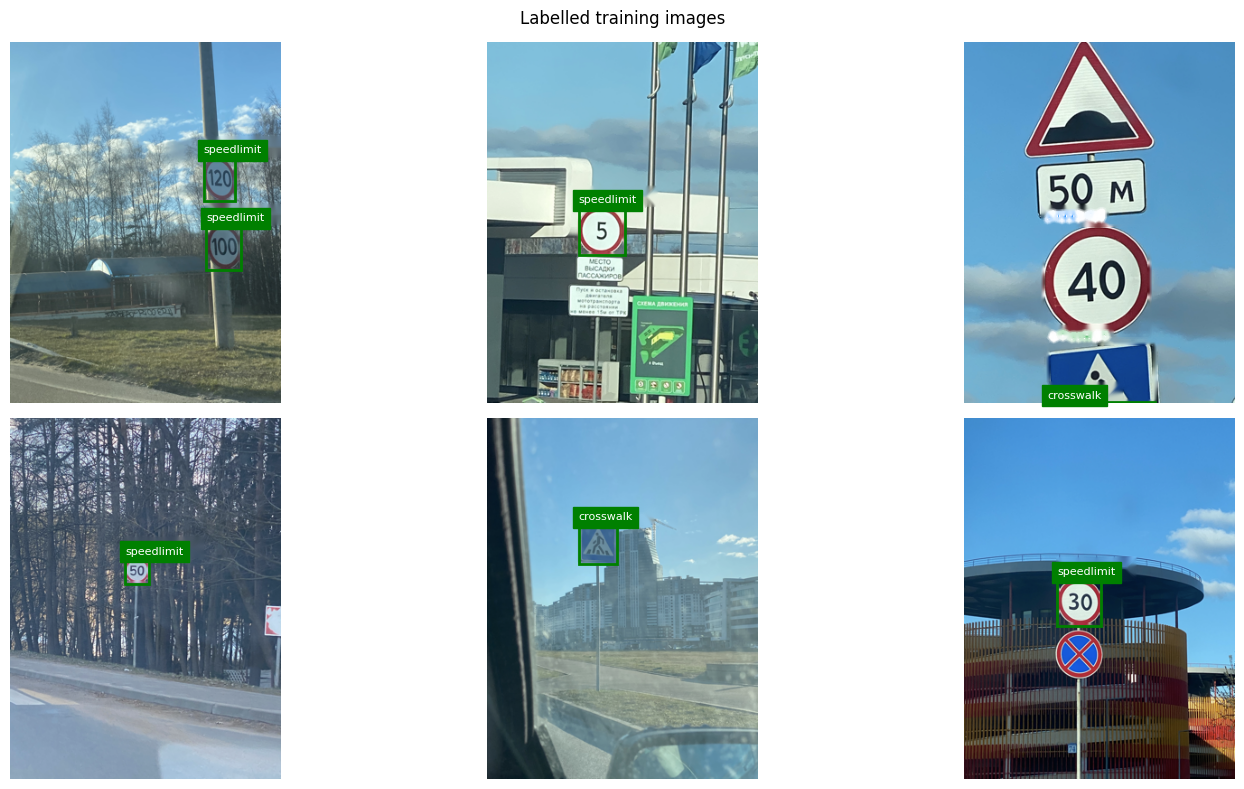

In [16]:
class DetectionDataset(Dataset):
    def __init__(self, samples, train=False):
        self.samples = samples
        self.train = train

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, objects = self.samples[idx]
        image = TF.to_tensor(open_image(img_path))
        boxes = torch.tensor([box for _, box in objects], dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor([class_to_id[name] for name, _ in objects], dtype=torch.int64)

        if self.train and random.random() < 0.5:  # random horizontal flip
            image = image.flip(-1)
            width = image.shape[-1]
            boxes[:, [0, 2]] = width - boxes[:, [2, 0]]

        return image, {'boxes': boxes, 'labels': labels}


def collate_fn(batch):
    return tuple(zip(*batch))


train_dataset = DetectionDataset(train_samples, train=True)
test_dataset = DetectionDataset(test_samples)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=2, collate_fn=collate_fn)

plt.figure(figsize=(16, 8))
for i in range(min(6, len(train_samples))):
    image, target = DetectionDataset(train_samples)[i]
    ax = plt.subplot(2, 3, i + 1)
    ax.imshow(image.permute(1, 2, 0))
    draw_boxes(ax, target['boxes'].tolist(), [class_names[l - 1] for l in target['labels'].tolist()], 'green')
    ax.axis('off')
plt.suptitle('Labelled training images')
plt.tight_layout()
plt.show()

## Block 17: Train Faster R-CNN on the labelled data

Epoch 1/15 - loss: 0.4686
Epoch 2/15 - loss: 0.2269
Epoch 3/15 - loss: 0.1767
Epoch 4/15 - loss: 0.1485
Epoch 5/15 - loss: 0.1263
Epoch 6/15 - loss: 0.1197
Epoch 7/15 - loss: 0.0912
Epoch 8/15 - loss: 0.0766
Epoch 9/15 - loss: 0.0631
Epoch 10/15 - loss: 0.0609
Epoch 11/15 - loss: 0.0599
Epoch 12/15 - loss: 0.0599
Epoch 13/15 - loss: 0.0604
Epoch 14/15 - loss: 0.0567
Epoch 15/15 - loss: 0.0553
Training time: 510.7 s


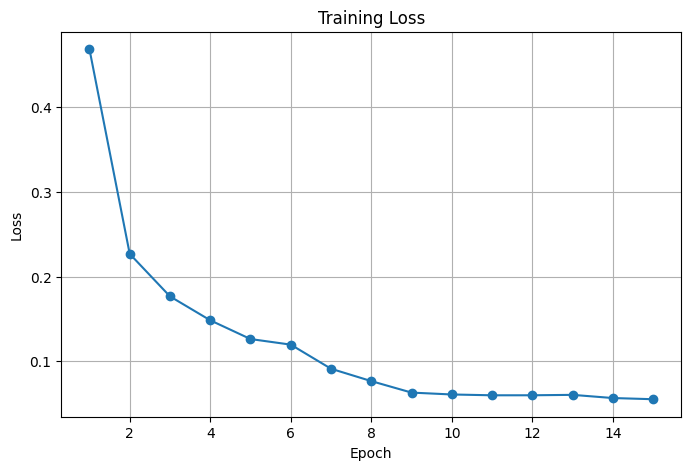

In [17]:
# Faster R-CNN pretrained on COCO, with a new classifier for our own classes
model = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, len(class_names) + 1)
model = model.to(device)

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=8, gamma=0.1)

num_epochs = 15
loss_history = []
start = time.time()
for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0.0
    for images, targets in train_loader:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    scheduler.step()
    loss_history.append(epoch_loss / len(train_loader))
    print(f"Epoch {epoch + 1}/{num_epochs} - loss: {loss_history[-1]:.4f}")

print(f"Training time: {time.time() - start:.1f} s")

plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), loss_history, marker='o')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

## Block 18: Test the model - IoU, precision, recall and mAP

In [18]:
model.eval()
test_predictions, test_ground_truths = [], []
with torch.no_grad():
    for images, targets in test_loader:
        outputs = model([img.to(device) for img in images])
        for out, t in zip(outputs, targets):
            test_predictions.append({'boxes': out['boxes'].cpu().tolist(),
                                     'scores': out['scores'].cpu().tolist(),
                                     'labels': out['labels'].cpu().tolist()})
            test_ground_truths.append({'boxes': t['boxes'].tolist(), 'labels': t['labels'].tolist()})


def evaluate_class(predictions, ground_truths, class_id, iou_threshold=0.5, score_threshold=0.5):
    # Ranks every detection of one class by score and uses calculate_iou and calculate_ap from above
    detections, gt_by_image, n_gt = [], {}, 0
    for i, (pred, gt) in enumerate(zip(predictions, ground_truths)):
        gt_by_image[i] = [box for box, l in zip(gt['boxes'], gt['labels']) if l == class_id]
        n_gt += len(gt_by_image[i])
        detections += [(s, i, box) for box, s, l in zip(pred['boxes'], pred['scores'], pred['labels']) if l == class_id]
    if n_gt == 0:
        return None

    detections.sort(key=lambda d: -d[0])
    matched = {i: set() for i in gt_by_image}
    tp = fp = 0
    precisions, recalls = [], []
    precision_at, recall_at = 0.0, 0.0
    for score, i, box in detections:
        best_iou, best_j = 0, -1
        for j, gt_box in enumerate(gt_by_image[i]):
            if j not in matched[i]:
                iou = calculate_iou(box, gt_box)
                if iou > best_iou:
                    best_iou, best_j = iou, j
        if best_iou >= iou_threshold:
            tp += 1
            matched[i].add(best_j)
        else:
            fp += 1
        precisions.append(tp / (tp + fp))
        recalls.append(tp / n_gt)
        if score >= score_threshold:
            precision_at, recall_at = precisions[-1], recalls[-1]

    return calculate_ap(precisions, recalls), precision_at, recall_at, n_gt


print(f"{'Class':20} {'Objects':>8} {'AP@0.5':>8} {'AP@0.75':>8} {'Precision':>10} {'Recall':>8}")
ap50_list, ap75_list = [], []
for name in class_names:
    cid = class_to_id[name]
    result50 = evaluate_class(test_predictions, test_ground_truths, cid, iou_threshold=0.5)
    result75 = evaluate_class(test_predictions, test_ground_truths, cid, iou_threshold=0.75)
    if result50 is None:
        print(f"{name:20} {'not in test set':>8}")
        continue
    ap50, precision, recall, n_gt = result50
    ap75 = result75[0]
    ap50_list.append(ap50)
    ap75_list.append(ap75)
    print(f"{name:20} {n_gt:8} {ap50:8.3f} {ap75:8.3f} {precision:10.3f} {recall:8.3f}")

print(f"\nmAP@0.5:  {np.mean(ap50_list):.3f}")
print(f"mAP@0.75: {np.mean(ap75_list):.3f}")
print("(Precision and recall are for detections with score >= 0.5)")

Class                 Objects   AP@0.5  AP@0.75  Precision   Recall
crosswalk                   8    0.829    0.732      0.636    0.875
speedlimit                 22    0.976    0.939      0.875    0.955
stop                        4    0.688    0.688      1.000    0.500
trafficlight                3    0.733    0.500      0.333    0.333

mAP@0.5:  0.806
mAP@0.75: 0.715
(Precision and recall are for detections with score >= 0.5)


## Block 19: Visualize test predictions

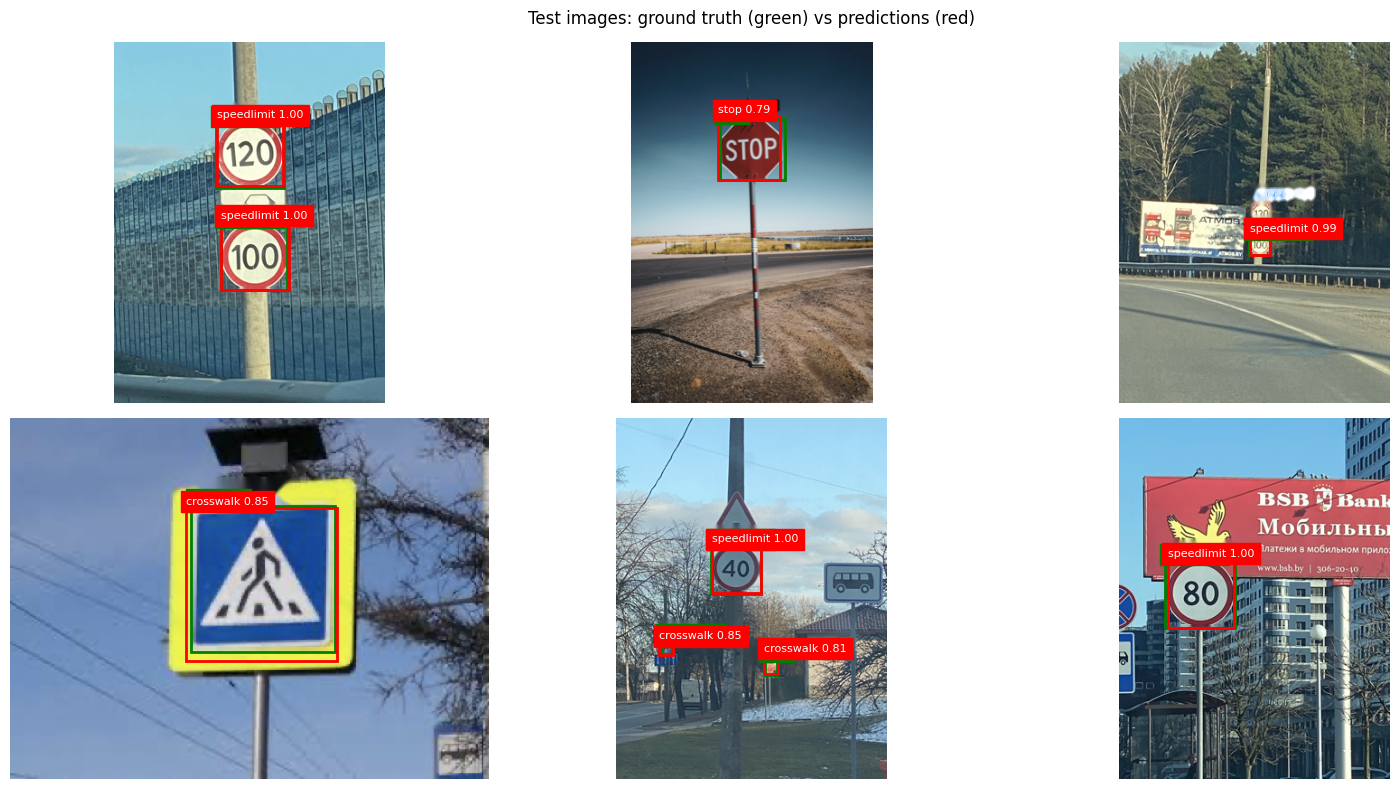

In [19]:
plt.figure(figsize=(16, 8))
for i in range(min(6, len(test_samples))):
    image, _ = test_dataset[i]
    pred, gt = test_predictions[i], test_ground_truths[i]
    ax = plt.subplot(2, 3, i + 1)
    ax.imshow(image.permute(1, 2, 0))
    draw_boxes(ax, gt['boxes'], [class_names[l - 1] for l in gt['labels']], 'green')
    keep = [k for k, s in enumerate(pred['scores']) if s >= 0.5]
    draw_boxes(ax, [pred['boxes'][k] for k in keep],
               [f"{class_names[pred['labels'][k] - 1]} {pred['scores'][k]:.2f}" for k in keep], 'red')
    ax.axis('off')
plt.suptitle('Test images: ground truth (green) vs predictions (red)')
plt.tight_layout()
plt.show()